Homework 6 - question 1 - part c

part i

In [18]:
import numpy as np
import scipy.optimize as opt
import matplotlib.pyplot as plt

In [9]:
pH = 0.5
rho = 0.5
tau = 5
N = 4 * 10**5

In [11]:
# Theoretical intake rate
def R(T):
    food = pH * (1 - np.exp(-rho*T))
    time = food/rho + (1-pH)*T + tau
    return food/time

# Expected marginal food acquisition rate
def lam(T):
    return (rho*pH*np.exp(-rho*T) /
            (pH*np.exp(-rho*T) + 1-pH))

In [13]:
# Find T* where R(T) = lambda(T)
T_star = opt.brentq(
    lambda T: R(T) - lam(T),
    0.001, 100
)

R_star = R(T_star)

print("T* =", T_star)
print("R* =", R_star)

T* = 4.181434810310969
R* = 0.05500115972326259


In [15]:
# Simulation
rng = np.random.default_rng(42)

for T in [2, T_star, 10]:

    # Determine patch type
    high = rng.random(N) < pH

    # Generate exponential waiting times
    waiting_time = rng.exponential(
        scale=1/rho, size=N
    )

    # Determine whether food is found
    food = high & (waiting_time <= T)

    # Time spent inside each patch
    patch_time = np.where(
        high,
        np.minimum(waiting_time, T),
        T
    )

    # Include travel time
    total_time = patch_time + tau

    # Calculate measured intake rate
    R_sim = food.sum() / total_time.sum()

    print(
        f"T = {T:.4f}, "
        f"Simulated R = {R_sim:.6f}, "
        f"Theoretical R = {R(T):.6f}"
    )


T = 2.0000, Simulated R = 0.047752, Theoretical R = 0.047656
T = 4.1814, Simulated R = 0.055094, Theoretical R = 0.055001
T = 10.0000, Simulated R = 0.045210, Theoretical R = 0.045176


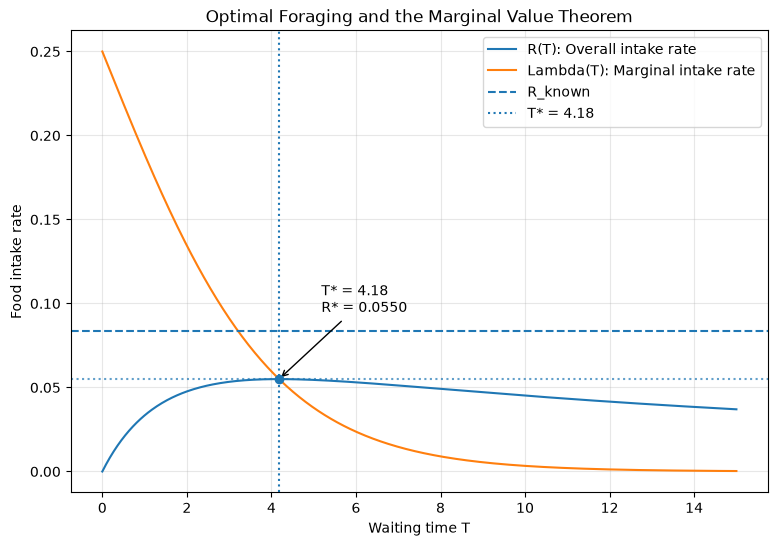

In [20]:
# Intake rate with known patch type
R_known = pH / (pH/rho + tau)

# Generate values for plotting
T = np.linspace(0, 15, 500)

# Plot
plt.figure(figsize=(9, 6))

plt.plot(T, R(T), label="R(T): Overall intake rate")
plt.plot(T, lam(T), label="Lambda(T): Marginal intake rate")
plt.axhline(
    R_known,
    linestyle="--",
    label="R_known"
)

# Mark optimal point
plt.scatter(T_star, R_star, zorder=5)

plt.axvline(
    T_star,
    linestyle=":",
    label=f"T* = {T_star:.2f}"
)

plt.axhline(
    R_star,
    linestyle=":",
    alpha=0.7
)

plt.annotate(
    f"T* = {T_star:.2f}\nR* = {R_star:.4f}",
    xy=(T_star, R_star),
    xytext=(T_star + 1, R_star + 0.04),
    arrowprops=dict(arrowstyle="->")
)

plt.xlabel("Waiting time T")
plt.ylabel("Food intake rate")
plt.title("Optimal Foraging and the Marginal Value Theorem")
plt.legend()
plt.grid(alpha=0.3)
plt.show()